# Falla per inestabilitat: disseny de la secció d'un suport
**Disseny i assaig de màquines** · Màster en Enginyeria Industrial (UdG)

Suport d'alumini 2014-T6 de secció rectangular $a \times b$ sotmès a una força de compressió centrada $P$. El suport és encastat-articulat en el pla $x$-$y$ i encastat-lliure en el pla $x$-$z$.

- **Apartat 1):** disseny de la secció de mínima àrea amb el mètode de Montecarlo, amb restriccions de resistència i de vinclament.
- **Apartat 2):** el mateix disseny plantejat com un problema d'optimització amb restriccions i resolt amb el mètode SLSQP.

Aquest quadern reprodueix l'script `DiAM_columna_SOL.py` i té la mateixa estructura que `DiAM_columna_SOL.m`.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

## Funcions emprades
- `suport`: àrea de la secció, coeficient de seguretat per resistència $\mathit{SF}_{res} = S_y/(P/A)$, càrregues crítiques d'Euler als dos plans i coeficient de seguretat per vinclament $\mathit{SF}_{cr} = P_{cr}/P$. Treballa amb vectors, de manera que avalua tots els dissenys alhora.
- `montecarlo`: genera $n$ parells $(a, b)$ uniformes a $(0, a_{\max}]$, selecciona els factibles i retorna el de secció mínima (Algorisme 1).
- `optimitzacio`: minimitza l'àrea $A = a\,b$ amb les restriccions de resistència i de vinclament pel mètode SLSQP de `scipy.optimize.minimize` (Algorisme 2). Compta les avaluacions del model i desa el punt de cada iteració.

In [2]:
# (en Python s'han de definir abans de cridar-les; en MatLab van al final)

def suport(a, b, L, P, E, Sy, K_xy, K_xz):
    """Coeficients de seguretat del suport per resistència i per vinclament.
    Accepta escalars o vectors de NumPy (a i b de la mateixa mida).
    Entrada: a, b [mm], L [mm], P [N], E, Sy [MPa], K_xy, K_xz [-]
    Sortida: A [mm^2], SF_res, SF_cr [-] i Pcr [N]
    """
    A = a*b                                     # àrea de la secció
    # Resistència a compressió
    sigma  = P/A                                # MPa, tensió de compressió
    SF_res = Sy/sigma                           # coeficient de seguretat per resistència
    # Vinclament en el pla x-y (flexió al voltant de z, encastat-articulat)
    I_z    = b*a**3/12
    Pcr_xy = np.pi**2*E*I_z/(K_xy*L)**2
    # Vinclament en el pla x-z (flexió al voltant de y, encastat-lliure)
    I_y    = a*b**3/12
    Pcr_xz = np.pi**2*E*I_y/(K_xz*L)**2
    # Càrrega crítica del suport: la menor dels dos plans
    Pcr    = np.minimum(Pcr_xy, Pcr_xz)
    SF_cr  = Pcr/P                              # coeficient de seguretat per vinclament
    return A, SF_res, SF_cr, Pcr


def montecarlo(n, a_max, L, P, E, Sy, K_xy, K_xz, SF, rng):
    """Mètode de Montecarlo (Algorisme 1).
    Genera n parells (a, b) uniformes a (0, a_max], selecciona els factibles
    i retorna el de secció mínima.
    """
    a = a_max*(1 - rng.random(n))               # uniforme a (0, a_max]
    b = a_max*(1 - rng.random(n))
    A, SF_res, SF_cr, Pcr = suport(a, b, L, P, E, Sy, K_xy, K_xz)
    factible = (SF_res >= SF) & (SF_cr >= SF)   # restriccions de disseny
    i_opt = np.flatnonzero(factible)[np.argmin(A[factible])]
    return dict(a=a, b=b, A=A, Pcr=Pcr, factible=factible,
                a_opt=a[i_opt], b_opt=b[i_opt], A_opt=A[i_opt], Pcr_opt=Pcr[i_opt])


def optimitzacio(x0, a_max, L, P, E, Sy, K_xy, K_xz, SF):
    """Optimització amb restriccions pel mètode SLSQP (Algorisme 2).
    min A = a*b  subjecte a  SF_res >= SF,  SF_cr >= SF  i  0 < a, b <= a_max
    Retorna el disseny òptim, el nombre d'avaluacions del model i
    l'historial de les iteracions.
    """
    n_aval = [0]                                # comptador d'avaluacions del model
    historial = [np.array(x0, dtype=float)]     # punts de cada iteració

    def objectiu(x):                            # funció objectiu: àrea de la secció
        n_aval[0] += 1
        A, _, _, _ = suport(x[0], x[1], L, P, E, Sy, K_xy, K_xz)
        return A

    def restriccions(x):                        # restriccions: g_i(x) >= 0
        n_aval[0] += 1
        a, b = x
        _, SF_res, _, _ = suport(a, b, L, P, E, Sy, K_xy, K_xz)
        Pcr_xy = np.pi**2*E*(b*a**3/12)/(K_xy*L)**2
        Pcr_xz = np.pi**2*E*(a*b**3/12)/(K_xz*L)**2
        return np.array([Pcr_xy/P - SF,         # vinclament pla x-y
                         Pcr_xz/P - SF,         # vinclament pla x-z
                         SF_res - SF])          # resistència

    sol = minimize(objectiu, x0, method='SLSQP',
               bounds=[(1e-3, a_max), (1e-3, a_max)],
               constraints={'type': 'ineq', 'fun': restriccions},
               options={'ftol': 1e-2, 'maxiter': 100},
               callback=lambda xk: historial.append(xk.copy()))
    return dict(a_opt=sol.x[0], b_opt=sol.x[1], A_opt=sol.fun, n_aval=n_aval[0],
                n_iter=sol.nit, exit=sol.success, historial=np.array(historial))

## Dades del problema
Especificacions del cas. La llavor del generador aleatori és fixa per poder reproduir els resultats.

In [3]:
# Geometria [mm]
L     = 500.0       # longitud del suport
a_max = 80.0        # valor màxim de les variables de disseny a i b
# Càrrega [N]
P     = 20e3        # força de compressió centrada
# Material: alumini 2014-T6 [MPa]
E     = 70e3        # mòdul d'elasticitat
Sy    = 212.0       # límit de fluència
# Especificacions de disseny
SF    = 2.5         # coeficient de seguretat (resistència i vinclament)
# Condicions de contorn: longitud efectiva Le = K*L
K_xy  = 0.7         # pla x-y: encastat-articulat
K_xz  = 2.0         # pla x-z: encastat-lliure
# Mètode de Montecarlo
n_MC  = [10**3, 10**4, 10**5, 10**6]   # nombre de realitzacions
rng   = np.random.default_rng(2030)    # llavor fixa per reproduir els resultats

## Solució analítica (apèndix)
El disseny més eficient té la mateixa esveltesa en els dos plans, $a/b = K_{xy}/K_{xz}$. Es fa servir com a referència per valorar la solució de Montecarlo.

In [4]:
A_res  = SF*P/Sy                                        # àrea mínima per resistència
ratio  = K_xy/K_xz                                      # a/b del disseny més eficient
b_an   = (12*(K_xz*L)**2*SF*P/(np.pi**2*E*ratio))**0.25
a_an   = ratio*b_an
A_an   = a_an*b_an
print(f"Solució analítica: a = {a_an:.2f} mm, b = {b_an:.2f} mm, A = {A_an:.1f} mm^2")
print(f"  (àrea mínima per resistència: {A_res:.1f} mm^2)\n")

Solució analítica: a = 13.89 mm, b = 39.69 mm, A = 551.3 mm^2
  (àrea mínima per resistència: 235.8 mm^2)



## Apartat 1): mètode de Montecarlo
Es repeteix el càlcul per a $n = 10^3$, $10^4$, $10^5$ i $10^6$ realitzacions i es mesura el temps de càlcul. La primera crida (escalfament) no es compta.

In [5]:
print("Apartat 1): mètode de Montecarlo")
print(f"{'n':>9} {'a [mm]':>8} {'b [mm]':>8} {'A [mm2]':>9} {'error A':>8} {'factibles':>10} {'temps [ms]':>11}")
montecarlo(1000, a_max, L, P, E, Sy, K_xy, K_xz, SF, rng)   # escalfament (no es compta)
res = []
for n in n_MC:
    t0 = time.perf_counter()
    R = montecarlo(n, a_max, L, P, E, Sy, K_xy, K_xz, SF, rng)
    dt = (time.perf_counter() - t0)*1e3                     # ms
    err = (R['A_opt'] - A_an)/A_an*100
    res.append(dict(n=n, a=R['a_opt'], b=R['b_opt'], A=R['A_opt'], err=err,
                    frac=R['factible'].mean(), t=dt))
    print(f"{n:9d} {R['a_opt']:8.2f} {R['b_opt']:8.2f} {R['A_opt']:9.1f} {err:7.2f}% "
          f"{R['factible'].mean()*100:9.1f}% {dt:11.1f}")
R_vis = montecarlo(10000, a_max, L, P, E, Sy, K_xy, K_xz, SF, rng)   # per al gràfic

Apartat 1): mètode de Montecarlo
        n   a [mm]   b [mm]   A [mm2]  error A  factibles  temps [ms]
     1000    15.55    39.62     615.9   11.72%      55.4%         0.4
    10000    14.58    39.55     576.6    4.58%      54.6%         1.8
   100000    13.91    39.73     552.4    0.20%      55.2%         9.1
  1000000    13.90    39.81     553.4    0.37%      55.1%        90.4


## Representació gràfica: dissenys factibles i no factibles
Mostra de $n = 10^4$ realitzacions. Les fronteres s'obtenen igualant cada coeficient de seguretat a $\mathit{SF}$; la zona factible és la que queda per sobre de les tres corbes.

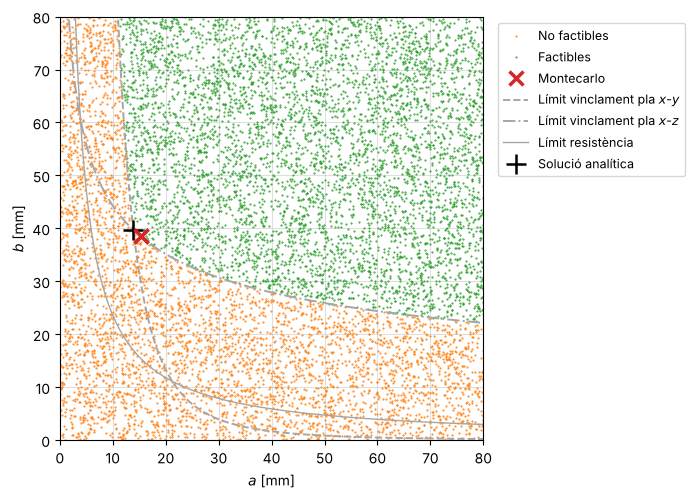

In [6]:
f = R_vis['factible']
plt.figure(figsize=(8.4, 5.5))
plt.plot(R_vis['a'][~f], R_vis['b'][~f], '.', markersize=1., color='tab:orange', label='No factibles')
plt.plot(R_vis['a'][f],  R_vis['b'][f],  '.', markersize=1., color='tab:green', label='Factibles')
plt.plot(R_vis['a_opt'], R_vis['b_opt'], 'x', color='tab:red', markersize=10, markeredgewidth=2.5, label='Montecarlo')

# Frontera analítica de vinclament en cada pla i de resistència
a_ = np.linspace(1, a_max, 400)
b_xy  = SF*P*12*(K_xy*L)**2/(np.pi**2*E*a_**3)        # Pcr_xy = SF*P
b_xz  = (SF*P*12*(K_xz*L)**2/(np.pi**2*E*a_))**(1/3)  # Pcr_xz = SF*P
b_res = A_res/a_                                        # A = A_res
plt.plot(a_,   b_xy,  '--', color='0.65', linewidth=1.4, label='Límit vinclament pla $x$-$y$')
plt.plot(a_,   b_xz,  '-.', color='0.65', linewidth=1.4, label='Límit vinclament pla $x$-$z$')
plt.plot(a_,   b_res, '-',  color='0.65', linewidth=1., label='Límit resistència')
plt.plot(a_an, b_an, 'k+', markersize=14, markeredgewidth=1.8, label='Solució analítica')
plt.plot(R_vis['a_opt'], R_vis['b_opt'], 'x', color='tab:red', markersize=10, markeredgewidth=2.5)

plt.xlim(0, a_max); plt.ylim(0, a_max)
plt.xlabel('$a$ [mm]'); plt.ylabel('$b$ [mm]')
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
plt.gca().set_aspect('equal')
plt.grid(True, alpha=0.4)
plt.savefig('Fig1_DiAM_columna_MC.pdf', bbox_inches='tight')
plt.show()

## Apartat 2): optimització amb restriccions (SLSQP)
$$\min_{a,b}\; A = a\,b \quad \text{subjecte a} \quad \frac{P_{cr,xy}}{P} \ge \mathit{SF},\; \frac{P_{cr,xz}}{P} \ge \mathit{SF},\; \mathit{SF}_{res} \ge \mathit{SF},\; 0 < a, b \le a_{\max}$$

El punt inicial és $(a_{\max}, a_{\max})$, que és factible.

In [7]:
x0 = [a_max, a_max]                                         # punt inicial factible
optimitzacio(x0, a_max, L, P, E, Sy, K_xy, K_xz, SF)        # escalfament (no es compta)
t0 = time.perf_counter()
R_opt = optimitzacio(x0, a_max, L, P, E, Sy, K_xy, K_xz, SF)
dt_opt = (time.perf_counter() - t0)*1e3                     # ms
err_opt = (R_opt['A_opt'] - A_an)/A_an*100
print("\nApartat 2): optimització amb restriccions (SLSQP)")
print(f"  punt inicial: a = {x0[0]:.0f} mm, b = {x0[1]:.0f} mm")
print(f"  solució: a = {R_opt['a_opt']:.3f} mm, b = {R_opt['b_opt']:.3f} mm, "
      f"A = {R_opt['A_opt']:.2f} mm^2 (error {abs(err_opt):.4f}%)")
print(f"  {R_opt['n_iter']} iteracions, {R_opt['n_aval']} avaluacions del model, "
      f"{dt_opt:.1f} ms, convergència: {R_opt['exit']}")
print("\n  Iteracions:")
for k, (ak, bk) in enumerate(R_opt['historial']):
    print(f"  {k:3d}  a = {ak:7.3f} mm  b = {bk:7.3f} mm  A = {ak*bk:8.2f} mm^2")


Apartat 2): optimització amb restriccions (SLSQP)
  punt inicial: a = 80 mm, b = 80 mm
  solució: a = 13.891 mm, b = 39.689 mm, A = 551.33 mm^2 (error 0.0000%)
  10 iteracions, 64 avaluacions del model, 2.5 ms, convergència: True

  Iteracions:
    0  a =  80.000 mm  b =  80.000 mm  A =  6400.00 mm^2
    1  a =  59.866 mm  b =  60.610 mm  A =  3628.48 mm^2
    2  a =  44.596 mm  b =  46.876 mm  A =  2090.48 mm^2
    3  a =  32.821 mm  b =  38.331 mm  A =  1258.04 mm^2
    4  a =  23.654 mm  b =  35.126 mm  A =   830.87 mm^2
    5  a =  17.852 mm  b =  36.209 mm  A =   646.40 mm^2
    6  a =  14.559 mm  b =  38.734 mm  A =   563.94 mm^2
    7  a =  13.900 mm  b =  39.654 mm  A =   551.18 mm^2
    8  a =  13.891 mm  b =  39.689 mm  A =   551.33 mm^2
    9  a =  13.891 mm  b =  39.689 mm  A =   551.33 mm^2


## Representació gràfica: camí de l'optimitzador
Iteracions de l'SLSQP sobre la zona factible i les corbes d'isoàrea.

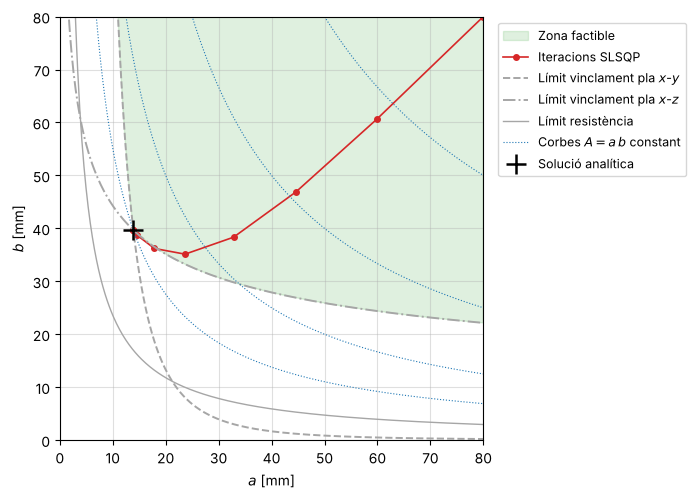

In [8]:
plt.figure(figsize=(8.4, 5.5))
# Zona factible: per sobre de les tres fronteres
b_lim = np.maximum.reduce([b_xy, b_xz, b_res])
plt.fill_between(a_, b_lim, a_max, color='tab:green', alpha=0.15, label='Zona factible')
H = R_opt['historial']
plt.plot(H[:, 0], H[:, 1], 'o-', color='tab:red', markersize=4, linewidth=1.2, label='Iteracions SLSQP')
plt.plot(a_,   b_xy,  '--', color='0.65', linewidth=1.4, label='Límit vinclament pla $x$-$y$')
plt.plot(a_,   b_xz,  '-.', color='0.65', linewidth=1.4, label='Límit vinclament pla $x$-$z$')
plt.plot(a_,   b_res, '-',  color='0.65', linewidth=1., label='Límit resistència')
# Corbes d'isoàrea
for Ak in [A_an, 1000, 2000, 4000]:
    plt.plot(a_, Ak/a_, ':', color='tab:blue', linewidth=0.8)
plt.plot([], [], ':', color='tab:blue', linewidth=0.8, label='Corbes $A = a\\,b$ constant')
plt.plot(a_an, b_an, 'k+', markersize=14, markeredgewidth=1.8, label='Solució analítica')
plt.xlim(0, a_max); plt.ylim(0, a_max)
plt.xlabel('$a$ [mm]'); plt.ylabel('$b$ [mm]')
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
plt.gca().set_aspect('equal')
plt.grid(True, alpha=0.4)
plt.savefig('Fig2_DiAM_columna_SLSQP.pdf', bbox_inches='tight')
plt.show()

## Apartat 3): validesa de la fórmula d'Euler
La fórmula d'Euler només és vàlida per a columnes llargues, amb una esveltesa superior a $(L_e/r)_1 = \sqrt{2\pi^2 E/S_y}$. Per sota d'aquest valor la columna és intermèdia i cal aplicar la fórmula de Johnson. Es representa el disseny òptim sobre les corbes de tensió crítica d'Euler i de Johnson.


Apartat 3): validesa de la fórmula d'Euler
  esveltesa límit (Le/r)_1 = 80.7
  esveltesa pla x-y = 87.3, pla x-z = 87.3
  tensió crítica de disseny = 90.7 MPa (Sy/2 = 106 MPa)
  -> columna llarga: Euler és aplicable


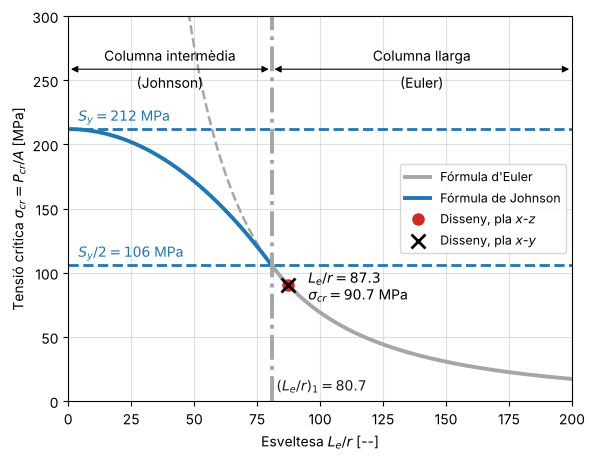

In [9]:
# Columna llarga (Euler) si Le/r >= (Le/r)_1; columna intermèdia (Johnson) si no
lam_1   = np.sqrt(2*np.pi**2*E/Sy)                  # esveltesa límit Euler-Johnson
lam_    = np.linspace(1, 200, 800)
sig_E   = np.pi**2*E/lam_**2                        # Euler
sig_J   = Sy - (Sy*lam_/(2*np.pi))**2/E             # Johnson
a_d, b_d = R_opt['a_opt'], R_opt['b_opt']           # disseny òptim (SLSQP)
lam_xy  = K_xy*L*np.sqrt(12)/a_d                    # esveltesa pla x-y (r_z = a/sqrt(12))
lam_xz  = K_xz*L*np.sqrt(12)/b_d                    # esveltesa pla x-z (r_y = b/sqrt(12))
sig_d   = SF*P/(a_d*b_d)                            # tensió crítica de disseny, Pcr/A
print("\nApartat 3): validesa de la fórmula d'Euler")
print(f"  esveltesa límit (Le/r)_1 = {lam_1:.1f}")
print(f"  esveltesa pla x-y = {lam_xy:.1f}, pla x-z = {lam_xz:.1f}")
print(f"  tensió crítica de disseny = {sig_d:.1f} MPa (Sy/2 = {Sy/2:.0f} MPa)")
print("  -> columna llarga: Euler és aplicable" if min(lam_xy, lam_xz) >= lam_1
      else "  -> columna intermèdia: cal aplicar Johnson")

plt.figure(figsize=(6.5, 5.0))
plt.plot(lam_[lam_ >= lam_1], sig_E[lam_ >= lam_1], '-', color='0.65', linewidth=2.8, label="Fórmula d'Euler")
plt.plot(lam_[lam_ <  lam_1], sig_E[lam_ <  lam_1], '--', color='0.65', linewidth=1.80)
plt.plot(lam_[lam_ <= lam_1], sig_J[lam_ <= lam_1], '-', color='tab:blue', linewidth=2.8, label="Fórmula de Johnson")
plt.axhline(Sy,   color='tab:blue', linestyle='--', linewidth=2.0)
plt.axhline(Sy/2, color='tab:blue', linestyle='--', linewidth=2.0)
plt.axvline(lam_1, color='0.65', linestyle='-.', linewidth=2.8)        # límit entre zones
plt.plot(lam_xz, sig_d, 'o', color='tab:red', markersize=8, label='Disseny, pla $x$-$z$')
plt.plot(lam_xy, sig_d, 'x', color='k', markersize=10, markeredgewidth=2, label='Disseny, pla $x$-$y$')

plt.text( 4, Sy/2 + 6, f'$S_y/2 = {Sy/2:.0f}$ MPa', fontsize=10, color='tab:blue')
plt.text( 4, Sy + 6, f'$S_y = {Sy:.0f}$ MPa', fontsize=10, color='tab:blue')
plt.text(lam_1 + 2, 8, f'$(L_e/r)_1 = {lam_1:.1f}$', fontsize=10, color='0.1')
plt.text(lam_xz + 8, sig_d - 12, f'$L_e/r = {lam_xz:.1f}$\n$\\sigma_{{cr}} = {sig_d:.1f}$ MPa', fontsize=10)
# Cotes de les dues zones
y_cota = 1.22*Sy
plt.annotate('', xy=(0, y_cota), xytext=(lam_1, y_cota),
             arrowprops=dict(arrowstyle='<|-|>', color='k', linewidth=0.8))
plt.annotate('', xy=(lam_1, y_cota), xytext=(200, y_cota),
             arrowprops=dict(arrowstyle='<|-|>', color='k', linewidth=0.8))
plt.text(lam_1/2, y_cota + 4, 'Columna intermèdia', ha='center', va='bottom', fontsize=10)
plt.text(lam_1/2, y_cota - 4, '(Johnson)', ha='center', va='top', fontsize=10)
plt.text((lam_1 + 200)/2, y_cota + 4, 'Columna llarga', ha='center', va='bottom', fontsize=10)
plt.text((lam_1 + 200)/2, y_cota - 4, '(Euler)', ha='center', va='top', fontsize=10)

plt.xlim(0, 200); plt.ylim(0, 300)
plt.xlabel('Esveltesa $L_e/r$ [--]')
plt.ylabel('Tensió crítica $\\sigma_{cr} = P_{cr}/A$ [MPa]')
plt.legend(loc='center right', fontsize=9)
plt.grid(True, alpha=0.4)
plt.savefig('Fig3_DiAM_columna_Euler_Johnson.pdf', bbox_inches='tight')
plt.show()

## Discussió
- La solució de Montecarlo sempre sobreestima l'àrea, perquè el mínim és a la frontera de la zona factible.
- L'error disminueix en augmentar $n$, però no de manera monòtona, i el temps de càlcul creix proporcionalment a $n$.
- La frontera de resistència queda dins la zona no factible: el disseny el governa el vinclament, i l'òptim és on es tallen les dues fronteres de vinclament.
- L'SLSQP arriba a la solució analítica en 10 iteracions i 64 avaluacions del model, davant de les $10^6$ avaluacions del Montecarlo, que encara té un error del 0,4 %.
- El disseny òptim té una esveltesa de 87,3 en els dos plans, superior a l'esveltesa límit $(L_e/r)_1 = 80{,}7$: la columna és llarga i la fórmula d'Euler és aplicable.